Student Performance Prediction Using Machine Learning
Project Type: Classification

Dataset Source: UCI Macine Learning Repository

Dataset: Student Performance(Mathematics)

The purpose of this project is to predict whether a student will pass or fail a mathematics course using machine learning.

The original dataset contains about 395 student records and 33 columns. It also includes info about students' ages and study habits as well as their previous academic failings, social activities, and even family background.

The target variable is being called Pass, this is creeated by using the students' final grade which will be presented as G3.
Pass = 1(Final grade of 10 or higher)
Pass= 0(Final grade below 10)

The prediction goal is to find out if students' traits and characteristics can help identify the students at risk of failing.

I'll be using a Logistic Regression to build a classification model to evaluate the performance by using the accuracy, percision and cross-validation.


In [99]:
import zipfile

with zipfile.ZipFile("/student.zip", "r") as zip_ref:
    zip_ref.extractall("/content/")

In [100]:
import pandas as pd

df = pd.read_csv("/content/student-mat.csv", sep=";")

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset Shape: (395, 33)

First 5 rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [101]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values in Each Column:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Total Missing Values:
0


Missing Values Analysis

I went through and checked the dataset for missing values using the pandas isnull and sum functions.

In turn this helped with identifying the incomplete records that can affect the accuracy of the machine learning model.

The end results gave me no missing values in the dataset. Which means for me, no missing value or row removal was needed.


In [102]:
print("Duplicate rows befre cleaning:")
print(df.duplicated().sum())

df = df.drop_duplicates()

print("\nDuplicate rows after cleaning:")
print(df.duplicated().sum())

print("\nDataset Shape after cleaning:")
print(df.shape)

Duplicate rows befre cleaning:
0

Duplicate rows after cleaning:
0

Dataset Shape after cleaning:
(395, 33)


Duplicate Records Analysis
I checked through the dataset for reoccuring records by using the duplicated() function.

Repeating records can affects the accuracy of the learning model if they repeat the same information.

The results in the end showed that there were no duplicates. Using the drop_duplicates trto remove any exisiting.

The dataset still has 395 rows and 33 columns respectively.

In [103]:
categorical_columns = df.select_dtypes(
    include=['object']
    ).columns

print("Categorical Variables and Their Unique Values:\n")

for col in categorical_columns:
  print(col, ":", df[col].unique())

Categorical Variables and Their Unique Values:

school : ['GP' 'MS']
sex : ['F' 'M']
address : ['U' 'R']
famsize : ['GT3' 'LE3']
Pstatus : ['A' 'T']
Mjob : ['at_home' 'health' 'other' 'services' 'teacher']
Fjob : ['teacher' 'other' 'services' 'health' 'at_home']
reason : ['course' 'other' 'home' 'reputation']
guardian : ['mother' 'father' 'other']
schoolsup : ['yes' 'no']
famsup : ['no' 'yes']
paid : ['no' 'yes']
activities : ['no' 'yes']
nursery : ['yes' 'no']
higher : ['yes' 'no']
internet : ['no' 'yes']
romantic : ['no' 'yes']


Categorical Variables Analysis

Looking at the categorical variables using the select_dtypes and the unique functions, gave me the ability to find and identify the different categories in each column and check for changeable values.

The results had shown that the variables were consistent. The gender column contained primarly F(Female) and M(Male), while other columns had only contained yes and/or no.

In [104]:
df["Pass"] = (df["G3"] >= 10).astype(int)

print("Pass/Fail Column:")
print(df["Pass"].unique())

print("\nPass/Fail Percentages:")
print(df["Pass"].value_counts(normalize=True) * 100)

Pass/Fail Column:
[0 1]

Pass/Fail Percentages:
Pass
1    67.088608
0    32.911392
Name: proportion, dtype: float64


After I created the target variable called "Pass" by using the final grade which was G3 in bracket. So students with a grade if 10 or higher were recognized as passing which is shown above as (1). For the former, the students who failed were shown as (0).

The end results showed 67.09%(rounded) of students had passed and that 32% had failed.

In [105]:
df = df.drop(columns=["G1", "G2", "G3"])

print("Dataset Shape After Dropping Features:")
print(df.shape)

print("\nRemaining Columns:")
print(df.columns.tolist())

Dataset Shape After Dropping Features:
(395, 31)

Remaining Columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'Pass']


Removing the Unnecessary Features

Removing the G1-G3 columns from the data was needed for the purpose of G3 being made with the idea to make the Pass target variable, and keeping it would make a data leak.
Then removing G1 and G2 was done to find out the student performance by using the student characteristics instead of their previous grades. So while removing the features, the dataset maintained 395 rows and 31 columns!

# **Outlier Analysis**

I used the boxplots to identify the potential outliers in the numerical variables age and abscences.

The age variable had shown little change, with a quite small number of potential outliers.

The absences variable however showed numerous high values, which helped indicate that some students had outstanding absences than others.

With the IQR method, I used it in order to identify the oustanding absence values. The next part was to study and remove the selected outliers before I start working on the prediction model.


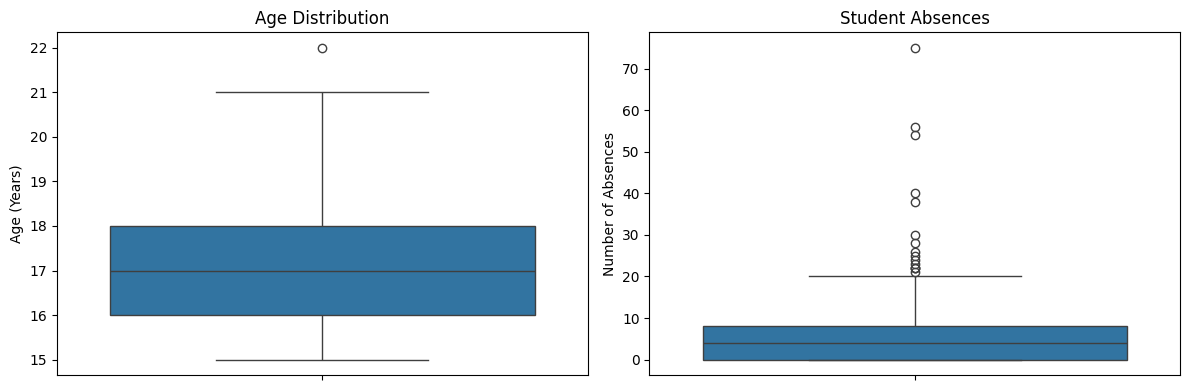

In [106]:
import matplotlib.pyplot as plt
import seaborn as sns

#Create a separate boxplot for age and absences
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(y=df["age"], ax=axes[0])
axes[0].set_title("Age Distribution")
axes[0].set_ylabel("Age (Years)")

sns.boxplot(y=df["absences"], ax=axes[1])
axes[1].set_title("Student Absences")
axes[1].set_ylabel("Number of Absences")

plt.tight_layout()
plt.show()



In [107]:
Q1 = df["absences"].quantile(0.25)
Q3 = df["absences"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 3 * IQR
upper_bound = Q3 + 3 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper Bound:", upper_bound)

outliers = df[
    (df["absences"] < lower_bound) |
    (df["absences"] > upper_bound)
]

print("\nNumber of extreme outliers:", len(outliers))
print("\nExtreme absence values:")
print(outliers["absences"].sort_values().tolist())

Q1: 0.0
Q3: 8.0
IQR: 8.0
Upper Bound: 32.0

Number of extreme outliers: 5

Extreme absence values:
[38, 40, 54, 56, 75]


In [108]:
print("Rows before removing outliers:", len(df))

df = df[
    (df["absences"] >= lower_bound) &
    (df["absences"] <= upper_bound)
].copy()

print("Rows after removing outliers:", len(df))
print("Outliers remaining:", (df["absences"] > upper_bound).sum())

Rows before removing outliers: 395
Rows after removing outliers: 390
Outliers remaining: 0


Outlier Removal

I used the boxplots to identify possible outliers in student age and absences. With the IQR method being used to identify extreme absence values.

The first quartile was 0, then the third was 8 and the IQR was 8. I was able to identify exactly 5 students with more than 32 absences.

In [109]:
# Select numerical features, excluding the target
numeric_features = df.select_dtypes(
    include=["int64", "float64", "int32"]
).drop(columns=["Pass"], errors="ignore")

# Calculate variance
variance = numeric_features.var()

print("Variance of Numerical Features:")
print(variance.sort_values())

print("\nZero Variance Features:")
print(variance[variance == 0])

Variance of Numerical Features:
traveltime     0.489651
failures       0.556984
studytime      0.708220
Dalc           0.800448
famrel         0.811423
freetime       0.984253
Fedu           1.191279
Medu           1.207890
goout          1.238580
age            1.615872
Walc           1.658328
health         1.928970
absences      33.967807
dtype: float64

Zero Variance Features:
Series([], dtype: float64)


In [110]:
from sklearn.feature_selection import f_classif
import pandas as pd

X_numeric = df.select_dtypes(include="number").drop(
    columns=["Pass"], errors="ignore"
)

y = df["Pass"]

f_scores, p_values = f_classif(X_numeric, y)

anova_results = pd.DataFrame({
    "Feature": X_numeric.columns,
    "F-Score": f_scores,
    "P-Value": p_values
})

anova_results = anova_results.sort_values(
    by="P-Value"
)

print("ANOVA Feature Selection Results:")
display(anova_results)

ANOVA Feature Selection Results:


,Feature,F-Score,P-Value
5,failures,51.591194,3.518244e-12
8,goout,14.337230,1.770122e-04
0,age,12.118783,5.559275e-04
1,Medu,6.003204,1.472084e-02
2,Fedu,4.992379,2.602809e-02
11,health,1.892483,1.697157e-01
4,studytime,1.842128,1.754907e-01
9,Dalc,1.396518,2.380312e-01
12,absences,1.293639,2.560802e-01
6,famrel,1.042294,3.079247e-01


Chi-Squared Feature Selection Analysis

I used the Chi-Squared test to examine the relationship between categorical variables and the Pass target variable. This test helps determine whether two categorical variables are statistically associated.

I used a significance level of 0.05. The results showed that higher and schoolsup were statistically significant, with p-values of 0.0077 and 0.0445.

The remaining 15 categorical variables had p-values above 0.05, meaning there was insufficient statistical evidence of an association with passing or failing. I will consider these results during feature selection, along with other analyses.

In [111]:
from scipy.stats import chi2_contingency
import pandas as pd

categorical_features = df.select_dtypes(
    include=["object"]
).columns

chi_results = []

for col in categorical_features:
    table = pd.crosstab(df[col], df["Pass"])

    chi2, p, dof, expected = chi2_contingency(table)

    chi_results.append({
        "Feature": col,
        "Chi-Square": chi2,
        "P-Value": p
    })

chi_df = pd.DataFrame(chi_results)
chi_df = chi_df.sort_values(by="P-Value")

print("Chi-Squared Test Results:")
display(chi_df)

Chi-Squared Test Results:


,Feature,Chi-Square,P-Value
14,higher,7.111433,0.007659
9,schoolsup,4.039054,0.044459
8,guardian,5.106434,0.077831
11,paid,2.853285,0.091187
16,romantic,2.461674,0.116654
7,reason,5.085784,0.165622
1,sex,1.724084,0.189168
15,internet,1.333933,0.248107
5,Mjob,5.113033,0.275895
10,famsup,1.074056,0.300031


In [112]:

# Convert categorical variables to numeric

# Separate the target variable
X = df.drop(columns=['Pass', 'G1', 'G2', 'G3'], errors='ignore')
y = df['Pass']

# Convert categorical variables into dummy variables
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Number of rows:", X.shape[0])
print("Number of features after encoding:", X.shape[1])
print("\nFirst five rows:")
display(X.head())


Number of rows: 390
Number of features after encoding: 39

First five rows:


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,1,0,1,0,0,0,1,1,0,0
1,17,1,1,1,2,0,5,3,3,1,...,0,0,0,1,0,0,0,1,1,0
2,15,1,1,1,2,3,4,3,2,2,...,1,0,1,0,1,0,1,1,1,0
3,15,4,2,1,3,0,3,2,2,1,...,1,0,0,1,1,1,1,1,1,1
4,16,3,3,1,2,0,4,3,2,1,...,0,0,0,1,1,0,1,1,0,0


I used a correlation heatmap to see if any of the features were strongly related to each other. Most of the colors were pretty light, which means most of the features did not have strong correlations. I noticed a few darker areas, but nothing that looked too extreme besides the diagonal red line, which just shows each feature compared to itself.

Based on the heatmap, I don't see any major correlation problems, but I would need to check the actual values to be sure. For now, I will keep the features and continue with the model.

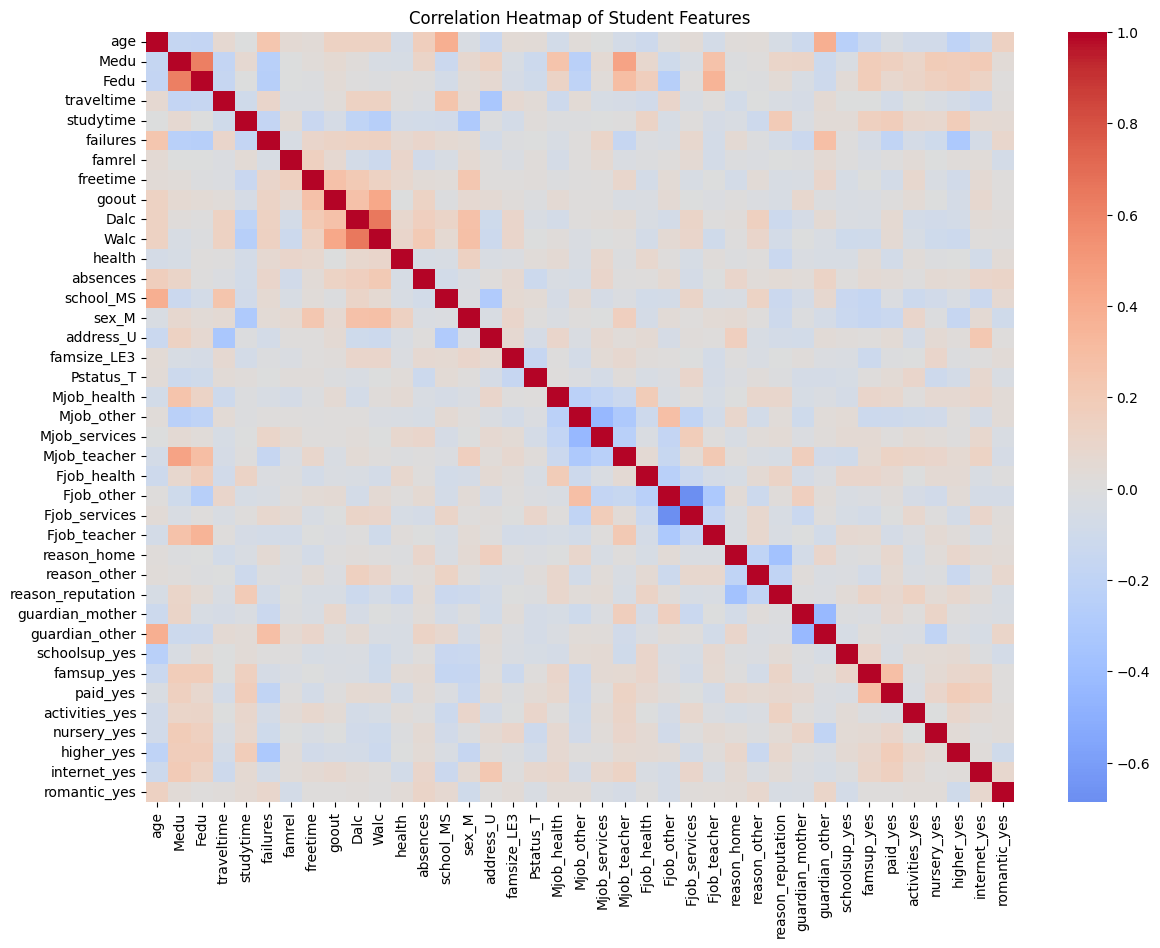

In [113]:

# Step 18: Check for highly correlated features

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation between numerical features
correlation_matrix = X.corr()

# Create correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Student Features")
plt.show()


In [114]:

# Find highly correlated features

import numpy as np

# Get absolute correlation values
corr_matrix = X.corr().abs()

# Look at only the upper half of the matrix
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Find feature pairs with correlation above 0.80
high_corr = upper.stack()
high_corr = high_corr[high_corr > 0.80]

print("Highly Correlated Feature Pairs:")
print(high_corr.sort_values(ascending=False))


Highly Correlated Feature Pairs:
Series([], dtype: float64)


In [115]:

#  Correlation Analysis

import numpy as np

# Calculate correlation between features
corr_matrix = X_encoded.corr().abs()

# only upper triangle to avoid duplicates
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Find highly correlated features
high_corr = [
    (column, row, upper.loc[row, column])
    for column in upper.columns
    for row in upper.index
    if pd.notna(upper.loc[row, column])
    and upper.loc[row, column] > 0.8
]

print("Highly correlated feature pairs (above 0.8):")

if high_corr:
    for feature1, feature2, value in high_corr:
        print(f"{feature1} and {feature2}: {value:.3f}")
else:
    print("No highly correlated feature pairs found.")


Highly correlated feature pairs (above 0.8):
No highly correlated feature pairs found.


In [116]:

# Low Variance Feature Analysis

from sklearn.feature_selection import VarianceThreshold

# Calculate variance for each feature
variances = X_encoded.var()

# Identify features with variance below 0.01
low_variance = variances[variances < 0.01]

print("Features with variance below 0.01:")

if len(low_variance) > 0:
    print(low_variance)
else:
    print("No low variance features found.")

print("\nTotal low variance features:", len(low_variance))


Features with variance below 0.01:
No low variance features found.

Total low variance features: 0


For this one I examined the distribution of passing and failing students
263 students had passed! While 127 had ultimately failed.
this in turn showed was imbalanced!

Pass/Fail Counts:
Pass
1    263
0    127
Name: count, dtype: int64

Pass/Fail Percentages:
Pass
1    67.435897
0    32.564103
Name: proportion, dtype: float64


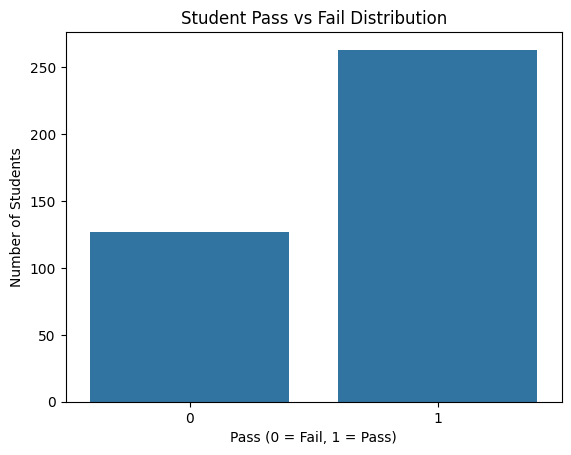

In [117]:

# Check class balance

import matplotlib.pyplot as plt
import seaborn as sns

# Count passing and failing students
print("Pass/Fail Counts:")
print(y.value_counts())

print("\nPass/Fail Percentages:")
print(y.value_counts(normalize=True) * 100)

# Create bar chart
sns.countplot(x=y)

plt.title("Student Pass vs Fail Distribution")
plt.xlabel("Pass (0 = Fail, 1 = Pass)")
plt.ylabel("Number of Students")
plt.show()


I examined the ANOVA F-scores and p-values to identify which features showed statistically significant differences between passing and failing students.

The strongest feature was previous class failures, which had an F-score of 51.59 and a very small p-value. This suggests that previous failures had a strong individual relationship with whether a student passed or failed.

A total of eight features had p-values below 0.05, indicating statistical significance. However, features with p-values above 0.05 were not statistically significant in this test, which does not necessarily mean they have no predictive value.

Based on these results, I considered features such as previous failures, going out, age, and higher-education plans.

Overall, the ANOVA F-test helped me understand which individual predictors had statistically significant relationships with the target variable and guided my feature-selection process.

In [118]:

## ANOVA F-Test

from sklearn.feature_selection import f_classif
import pandas as pd

# Perform ANOVA F-test
f_scores, p_values = f_classif(X_encoded, y)

# Create results table
anova_results = pd.DataFrame({
    "Feature": X_encoded.columns,
    "F-Score": f_scores,
    "P-Value": p_values
})

# Sort by p-value
anova_results = anova_results.sort_values("P-Value")

print("ANOVA F-Test Results:")
print(anova_results.to_string(index=False))


ANOVA F-Test Results:
          Feature   F-Score      P-Value
         failures 51.591194 3.518244e-12
            goout 14.337230 1.770122e-04
              age 12.118783 5.559275e-04
       higher_yes  8.658300 3.451239e-03
             Medu  6.003204 1.472084e-02
             Fedu  4.992379 2.602809e-02
    schoolsup_yes  4.747972 2.993389e-02
   guardian_other  4.528436 3.396587e-02
         paid_yes  3.241615 7.256634e-02
     romantic_yes  2.842095 9.262838e-02
      Mjob_health  2.435352 1.194425e-01
reason_reputation  2.337510 1.271061e-01
       Mjob_other  2.090801 1.489957e-01
            sex_M  2.019959 1.560466e-01
           health  1.892483 1.697157e-01
        studytime  1.842128 1.754907e-01
     internet_yes  1.686182 1.948763e-01
             Dalc  1.396518 2.380312e-01
       famsup_yes  1.313946 2.523879e-01
         absences  1.293639 2.560802e-01
    Mjob_services  1.236437 2.668473e-01
        Pstatus_T  1.158786 2.823863e-01
        address_U  1.081544 2.99000

In [119]:

# Select Significant Features

significant_features = anova_results[
    anova_results["P-Value"] < 0.05
]["Feature"].tolist()

print("Significant Features:")
for feature in significant_features:
    print(feature)

print("\nTotal Significant Features:",
      len(significant_features))


Significant Features:
failures
goout
age
higher_yes
Medu
Fedu
schoolsup_yes
guardian_other

Total Significant Features: 8


In [120]:

#  Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining features:", X_train.shape[1])
print("Testing features:", X_test.shape[1])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())


Training samples: 312
Testing samples: 78

Training features: 39
Testing features: 39

Training class distribution:
Pass
1    210
0    102
Name: count, dtype: int64

Testing class distribution:
Pass
1    53
0    25
Name: count, dtype: int64


In [121]:

#  Feature Scaling

from sklearn.preprocessing import StandardScaler
import pandas as pd

# Create the scaler
scaler = StandardScaler()

# Fit only on training data
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Apply the same transformation to testing data
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Scaled Training Data:")
print(X_train_scaled.head())

print("\nTraining shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)


Scaled Training Data:
          age      Medu      Fedu  traveltime  studytime  failures    famrel  \
335  0.279499  0.203754  1.324653   -0.657806   1.151550 -0.465357  0.098788   
190 -0.506121 -0.704406  0.410291   -0.657806  -0.026429 -0.465357  0.098788   
178 -0.506121  1.111913 -0.504072   -0.657806  -1.204408 -0.465357  0.098788   
109 -0.506121  1.111913  1.324653   -0.657806   1.151550 -0.465357  1.199565   
256  0.279499  1.111913 -0.504072   -0.657806   2.329530 -0.465357  0.098788   

     freetime     goout      Dalc  ...  guardian_mother  guardian_other  \
335  0.713974  1.736672 -0.541400  ...         0.651658       -0.288675   
190 -0.312569 -0.081589 -0.541400  ...         0.651658       -0.288675   
178 -0.312569 -0.081589  1.666664  ...         0.651658       -0.288675   
109  0.713974  1.736672 -0.541400  ...         0.651658       -0.288675   
256 -1.339113 -0.081589 -0.541400  ...         0.651658       -0.288675   

     schoolsup_yes  famsup_yes  paid_yes  acti

In [122]:

#  Train Logistic Regression Model

from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(
    random_state=42,
    max_iter=1000,
    class_weight="balanced"
)

# Train the model
model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

print("\nTraining accuracy:",
      round(model.score(X_train_scaled, y_train), 4))

print("Number of features used:",
      model.n_features_in_)


Logistic Regression model trained successfully!

Training accuracy: 0.7372
Number of features used: 39


In [123]:

#  Make Predictions

# Predict pass or fail
y_pred = model.predict(X_test_scaled)

# Display the first 10 predictions
print("First 10 Predictions:")
print(y_pred[:10])

print("\nFirst 10 Actual Results:")
print(y_test.iloc[:10].values)

print("\nTotal Predictions:", len(y_pred))


First 10 Predictions:
[1 0 0 0 0 0 1 1 0 0]

First 10 Actual Results:
[1 1 0 1 1 1 1 1 1 0]

Total Predictions: 78


In [124]:

#  Evaluate Model Performance

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Logistic Regression Model Evaluation")
print("------------------------------------")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))


Logistic Regression Model Evaluation
------------------------------------
Accuracy: 0.6282
Precision: 0.7222
Recall: 0.7358
F1-Score: 0.729


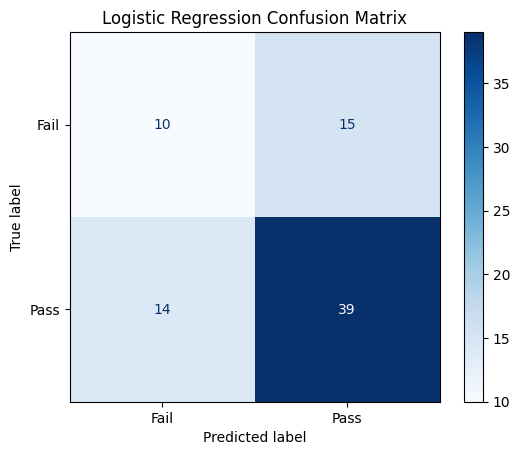

Confusion Matrix:
[[10 15]
 [14 39]]


In [125]:

# Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fail", "Pass"]
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

# Print numerical results
print("Confusion Matrix:")
print(cm)


In [126]:

#Train Model with Selected Features

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Select 8 features using training data only
selector = SelectKBest(score_func=f_classif, k=8)

X_train_selected = selector.fit_transform(
    X_train_scaled, y_train
)

X_test_selected = selector.transform(X_test_scaled)

# Train a new Logistic Regression model
selected_model = LogisticRegression(
    random_state=42,
    max_iter=1000,
    class_weight="balanced"
)

selected_model.fit(X_train_selected, y_train)

# Make predictions
y_pred_selected = selected_model.predict(X_test_selected)

# Evaluate
print("Selected Features:")
print(X_train_scaled.columns[selector.get_support()].tolist())

print("\nModel Comparison:")
print("Original Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("Selected Features Accuracy:",
      round(accuracy_score(y_test, y_pred_selected), 4))

print("\nOriginal F1-Score:",
      round(f1_score(y_test, y_pred), 4))

print("Selected Features F1-Score:",
      round(f1_score(y_test, y_pred_selected), 4))


Selected Features:
['age', 'Medu', 'Fedu', 'failures', 'goout', 'guardian_other', 'schoolsup_yes', 'higher_yes']

Model Comparison:
Original Accuracy: 0.6282
Selected Features Accuracy: 0.6538

Original F1-Score: 0.729
Selected Features F1-Score: 0.7523


In [127]:

#  Cross-Validation

from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create a pipeline
cv_model = Pipeline([
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(f_classif, k=8)),
    ("classifier", LogisticRegression(
        random_state=42,
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Use training data only
cv_scores = cross_val_score(
    cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Cross-Validation Accuracy Scores:")
print(cv_scores)

print("\nMean Accuracy:",
      round(cv_scores.mean(), 4))

print("Standard Deviation:",
      round(cv_scores.std(), 4))


Cross-Validation Accuracy Scores:
[0.61904762 0.65079365 0.77419355 0.56451613 0.66129032]

Mean Accuracy: 0.654
Standard Deviation: 0.0689


In [128]:

# Final Model Summary

print("STUDENT PERFORMANCE PREDICTION")
print("--------------------------------")

print("Algorithm: Logistic Regression")
print("Original Features: 39")
print("Selected Features: 8")

print("\nOriginal Model Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("Selected Model Accuracy:",
      round(accuracy_score(y_test, y_pred_selected), 4))

print("Selected Model F1-Score:",
      round(f1_score(y_test, y_pred_selected), 4))

print("Cross-Validation Mean Accuracy:",
      round(cv_scores.mean(), 4))

print("Cross-Validation Standard Deviation:",
      round(cv_scores.std(), 4))

print("\nConclusion:")
print("Feature selection improved model performance.")
print("However, prediction accuracy remains limited.")
print("Further improvements may require additional")
print("data, feature engineering, or model tuning.")


STUDENT PERFORMANCE PREDICTION
--------------------------------
Algorithm: Logistic Regression
Original Features: 39
Selected Features: 8

Original Model Accuracy: 0.6282
Selected Model Accuracy: 0.6538
Selected Model F1-Score: 0.7523
Cross-Validation Mean Accuracy: 0.654
Cross-Validation Standard Deviation: 0.0689

Conclusion:
Feature selection improved model performance.
However, prediction accuracy remains limited.
Further improvements may require additional
data, feature engineering, or model tuning.


# Conclusion

The goal of the project was to tell if students who would take a mathematics course would pass or fail by using machine learning.

I used the logistic regression since the target variable was binary (1 or 0) meaning it represented the passing or failing aspect.

The original model had used 39 encoded features and achieved an accuracy of 62%. After adding ANOVA feature selection, i was able to have the reduced number of features to eight which improved the accuracy to 65% and the F1 score to 75%.

Althought the feature selection improved the model's performance, the accuracy had remained below the majority-class bassline of around 67%. This showed that the model had limited it ability to predict and needed further improvement.

Testing Additional classification algorithms, tuning model parameters, and using a more informative stdent are some of the ways to possibly improve the model.

In conclusion, the project has shown the upmost importance of data cleaning, feature selection and model evaluation when making and developing a machine learning classification model.




##Reference

UCI Machine Learning Repository. Student Performance Dataset.
https://archive.ics.uci.edu/dataset/320/student+performance?